# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
# from google.colab import files   # Colab only: it opens the upload dialog. The dataset ships in ./dataset here.

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
df = pd.read_csv("dataset/Lab_11_QnA_Dataset.csv")   # the handout reads /content/Lab_11_QnA_Dataset_Download.csv
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

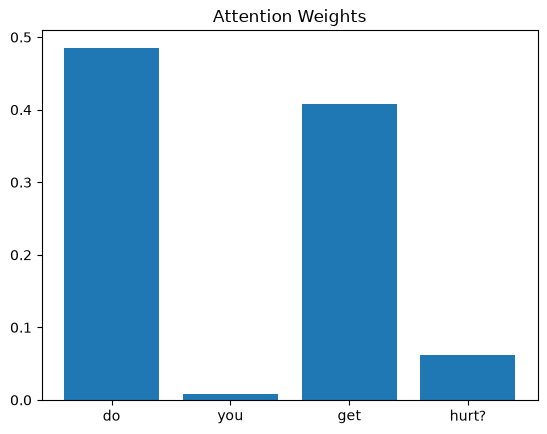

In [6]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

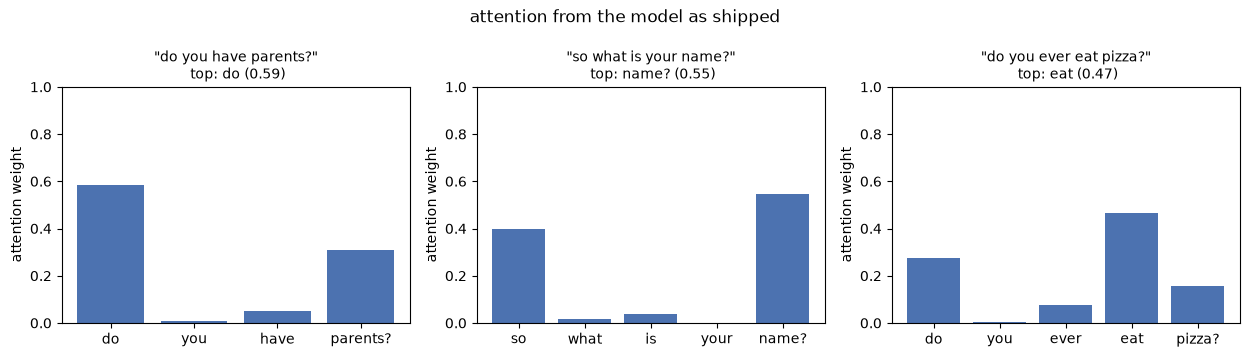

embedding output: (3, 11, 16) = (questions, words, 16)
RNN output:       (3, 11, 32)  - dim 0 is time, so it walks the 3 questions and sees the 11 word positions as a batch
train accuracy of the shipped model: 0.381


train accuracy of the fixed model:   1.000


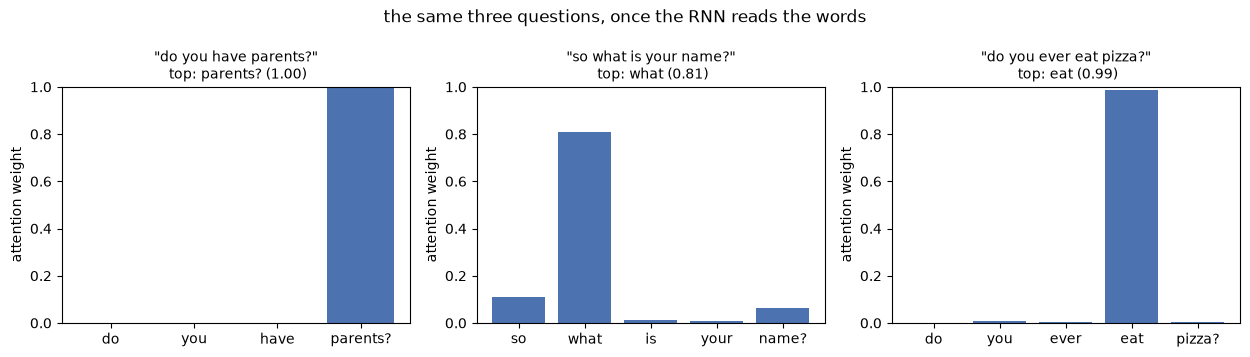

question                shipped: top word       fixed: top word         
do you have parents?    do (0.59)               parents? (1.00)         
so what is your name?   name? (0.55)            what (0.81)             
do you ever eat pizza?  eat (0.47)              eat (0.99)              


seen questions:   1.000
unseen questions: 0.588   (always predicting the commonest answer: 0.206)


In [7]:
import numpy as np

# Three questions, three charts - from the model exactly as the notebook trains it.
questions = ["do you have parents?", "so what is your name?", "do you ever eat pizza?"]

def attention(net, question):
    """Return (words, weights over those words, gold answer) for one question."""
    row = df.index[df["question"] == question][0]
    with torch.no_grad():
        _, weights = net(X[row:row + 1])
    words = question.split()
    return words, weights[0, :len(words)].tolist(), df["answer"][row]

def plot_attention(net, questions, suptitle):
    fig, axes = plt.subplots(1, len(questions), figsize=(4.2 * len(questions), 3.6))
    for ax, question in zip(np.atleast_1d(axes), questions):
        words, weights, _ = attention(net, question)
        top = max(range(len(words)), key=weights.__getitem__)
        ax.bar(words, weights, color="#4c72b0")
        ax.set_title(f'"{question}"\n top: {words[top]} ({weights[top]:.2f})', fontsize=10)
        ax.set_ylabel("attention weight")
        ax.set_ylim(0, 1)
    fig.suptitle(suptitle)
    fig.tight_layout()
    plt.show()

plot_attention(model, questions, "attention from the model as shipped")

# Does the recurrence even read the words? nn.RNN defaults to batch_first=False,
# so it treats dim 0 as time. X is (questions, words, features) - the wrong way round.
emb = model.emb(X[:3])
hidden, _ = model.rnn(emb)
print("embedding output:", tuple(emb.shape), "= (questions, words, 16)")
print("RNN output:      ", tuple(hidden.shape), " - dim 0 is time, so it walks the "
      f"{emb.shape[0]} questions and sees the {emb.shape[1]} word positions as a batch")

with torch.no_grad():
    logits, _ = model(X)
print(f"train accuracy of the shipped model: {float((logits.argmax(1) == y).float().mean()):.3f}")

# The same shape of model, with three things put right:
#   batch_first=True so the RNN walks the words,
#   optimizer.zero_grad() so gradients do not accumulate over the 50 steps,
#   -inf on the padding so it cannot collect attention weight.
class AttentionRNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16, padding_idx=0)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        hidden, _ = self.rnn(self.emb(x))
        scores = self.att(hidden).squeeze(-1).masked_fill(x == 0, float("-inf"))
        weights = torch.softmax(scores, dim=1)
        return self.fc((hidden * weights.unsqueeze(-1)).sum(1)), weights

torch.manual_seed(0)
fixed = AttentionRNN()
optimizer = torch.optim.Adam(fixed.parameters(), lr=0.01)
for epoch in range(400):
    optimizer.zero_grad()
    loss = nn.functional.cross_entropy(fixed(X)[0], y)
    loss.backward()
    optimizer.step()

with torch.no_grad():
    logits, _ = fixed(X)
print(f"train accuracy of the fixed model:   {float((logits.argmax(1) == y).float().mean()):.3f}")
plot_attention(fixed, questions, "the same three questions, once the RNN reads the words")

# Side by side: the model as shipped against the one that reads the words.
print(f'{"question":<24}{"shipped: top word":<24}{"fixed: top word":<24}')
for question in questions:
    row = []
    for net in (model, fixed):
        words, weights, _ = attention(net, question)
        top = max(range(len(words)), key=weights.__getitem__)
        row.append(f"{words[top]} ({weights[top]:.2f})")
    print(f"{question:<24}{row[0]:<24}{row[1]:<24}")

# 1.000 is on the questions the model was trained on. Hold out 20% and ask again.
order = np.random.RandomState(0).permutation(len(df))
cut = int(0.8 * len(df))
train_rows, test_rows = order[:cut], order[cut:]

torch.manual_seed(0)
held = AttentionRNN()
optimizer = torch.optim.Adam(held.parameters(), lr=0.01)
for epoch in range(400):
    optimizer.zero_grad()
    loss = nn.functional.cross_entropy(held(X[train_rows])[0], y[train_rows])
    loss.backward()
    optimizer.step()

with torch.no_grad():
    seen = float((held(X[train_rows])[0].argmax(1) == y[train_rows]).float().mean())
    unseen = float((held(X[test_rows])[0].argmax(1) == y[test_rows]).float().mean())
majority = float(np.bincount(y[test_rows].numpy()).max() / len(test_rows))
print(f"seen questions:   {seen:.3f}")
print(f"unseen questions: {unseen:.3f}   (always predicting the commonest answer: {majority:.3f})")

#### Answer

**Three questions, the model as the notebook trains it**

| question | highest weight |
|---|---|
| `do you have parents?` | `do` (0.59) |
| `so what is your name?` | `name?` (0.55) |
| `do you ever eat pizza?` | `eat` (0.47) |

At face value these are believable: two of the three land on a word that matters. They are
not believable, because two bugs sit under them.

`nn.RNN(16, 32)` is built without `batch_first=True`, and PyTorch then reads dim 0 as time.
`X` holds one row of word ids per question, `(168, 11)`, so the embedding comes out
`(168, 11, 16)` and the recurrence walks **across the 168 questions**, treating the 11 word
positions as a batch of 11. It never reads `do -> you -> have -> parents?`. The training loop
never calls `optimizer.zero_grad()` either, so each of the 50 steps starts from the previous
step's gradients instead of from zero.

The tell is the accuracy: **0.381 on the very data it was trained on**. With 168 examples and
12 classes, a model allowed to memorise should reach 1.000. This one cannot, because nothing in
its recurrence identifies the question.

**After the three fixes** - `batch_first=True`, `zero_grad()` every step, and padding masked
to `-inf` so it cannot collect weight - training accuracy is **1.000** and the same three
questions give:

| question | shipped model | fixed model |
|---|---|---|
| `do you have parents?` | `do` (0.59) | `parents?` (1.00) |
| `so what is your name?` | `name?` (0.55) | `what` (0.81) |
| `do you ever eat pizza?` | `eat` (0.47) | `eat` (0.99) |

**So, do the words with the highest weight look important?** Sometimes yes, not reliably.

- `parents?` and `eat` are exactly the words the answer turns on. Remove them and the question
  becomes ambiguous. The fixed model puts almost all of its weight there, which is what we hope
  attention does.
- `what` is not. In "so what is your name?" it takes 0.81 while `name?` - the word that decides
  between the twelve answers - takes 0.06. The model has learned that `what` is a good cue for
  this answer, and it is right often enough in these 168 questions to be worth 0.81.
- And the eye can be fooled by the question set. The model has been trained on every one of the
  168 questions, so a high weight on `parents?` may be a lookup rather than an understanding.
  With 20% held out, the same architecture scores **1.000 on questions it has seen and 0.588 on
  questions it has not** (always answering the commonest answer: 0.206). It does generalise from
  keywords - but that is a long way from reading the question.

Attention is a good debugging lens: it tells you *where the model reads*. It is not an
explanation of *why the answer is right*, and it is not evidence that the model understood.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

answer group: I don't have a name.
  'do you have a name?'      shipped  top 'name?'   0.92  all: [0.06, 0.0, 0.01, 0.01, 0.92]
  'do you have a name?'      fixed    top 'name?'   1.00  all: [0.0, 0.0, 0.0, 0.0, 1.0]
  'so what is your name?'    shipped  top 'name?'   0.55  all: [0.4, 0.02, 0.04, 0.0, 0.55]
  'so what is your name?'    fixed    top 'what'    0.81  all: [0.11, 0.81, 0.01, 0.01, 0.06]


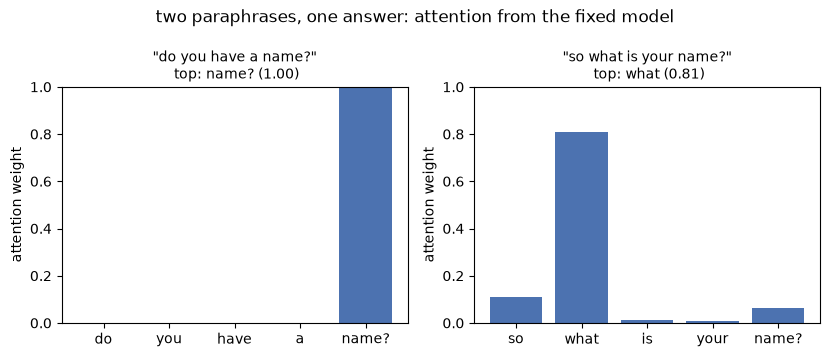

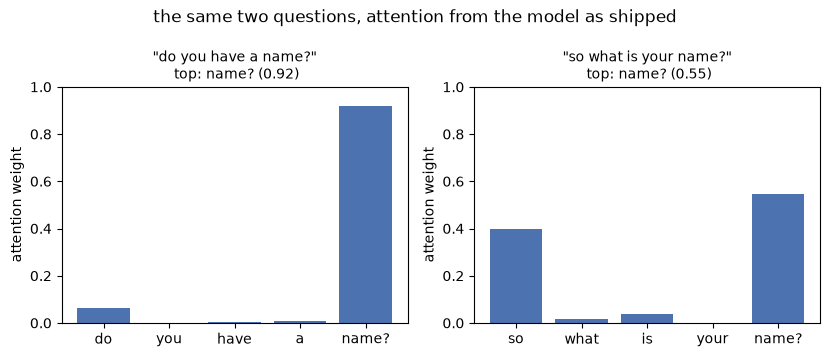

  'who created you?'   top 'created' 0.83  all: [0.05, 0.83, 0.11]
  'who built you?'     top 'built'   0.84  all: [0.06, 0.84, 0.09]


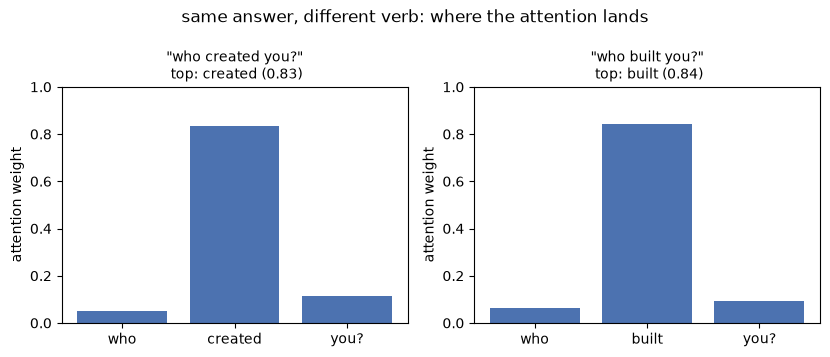

In [8]:
# Two ways of asking for the same answer.
pair = ["do you have a name?", "so what is your name?"]
print("answer group:", df["answer"][df.index[df["question"] == pair[0]][0]])

for question in pair:
    for label, net in (("shipped", model), ("fixed", fixed)):
        words, weights, _ = attention(net, question)
        top = max(range(len(words)), key=weights.__getitem__)
        print(f'  {question!r:<26} {label:<8} top {words[top]!r:<9} {weights[top]:.2f}  '
              f'all: {[round(w, 2) for w in weights]}')

plot_attention(fixed, pair, "two paraphrases, one answer: attention from the fixed model")
plot_attention(model, pair, "the same two questions, attention from the model as shipped")

# Two more paraphrases, but this time the word that carries the meaning is the verb.
pair2 = ["who created you?", "who built you?"]
for question in pair2:
    words, weights, _ = attention(fixed, question)
    top = max(range(len(words)), key=weights.__getitem__)
    print(f'  {question!r:<20} top {words[top]!r:<9} {weights[top]:.2f}  '
          f'all: {[round(w, 2) for w in weights]}')

plot_attention(fixed, pair2, "same answer, different verb: where the attention lands")

#### Answer

**Two wordings of the same question** - both answered "I don't have a name."

| question | shipped model | fixed model |
|---|---|---|
| `do you have a name?` | `name?` (0.92) | `name?` (1.00) |
| `so what is your name?` | `name?` (0.55) | `what` (0.81) |

The fixed model looks at **different words**: `name?` for the first, `what` for the second,
with `name?` down at 0.06 in the second even though it is the word that carries the meaning.

**A second pair, where the meaning sits in the verb** - both answered "People created me."

| question | highest weight |
|---|---|
| `who created you?` | `created` (0.83) |
| `who built you?` | `built` (0.84) |

Here the model looks at the **same slot** - the verb - but at two different strings.

**Does it focus on similar or different words?** Different words, but a consistent *role*. The
weights are computed from the hidden state of that exact question, not by matching words against
each other, so two questions with the same answer can be routed through different tokens and
still land on the same output. What the model has learned is "the content word (or the verb) is
where the answer lives", not "`created` and `built` mean the same thing".

**What this suggests about attention**

- The weights are per-instance, and nothing forces them to agree across paraphrases. Same answer,
  different route - so a single weight is not the reason for a prediction.
- Attention is a soft lookup that decides *which positions to pool*. A word with a small weight
  can still matter: its information may also reach the output through the pooled sum, and the
  softmax has to split a fixed budget of 1.0 across the tokens.
- Note which model looks more consistent on the first pair: the **shipped** one, at `name?` both
  times. That is the model whose recurrence does not read the words at all. A broken model that
  smooths everything into one direction is not more explainable, it is just less informative.
  Consistency of attention is not evidence that the attention is faithful.
- Practical reading: use attention to diagnose, not to justify. If a deployed system has to
  explain itself, the weight map is not enough - you need an intervention (delete the word and
  watch the answer change) or a model whose attention is supervised to mean something.